# Analyse exploratoire des données fusionnées

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROCESSED = Path("../data/processed")
trips    = pd.read_parquet(PROCESSED / "trips.parquet")
stations = pd.read_parquet(PROCESSED / "stations.parquet")
status   = pd.read_parquet(PROCESSED / "stations_status.parquet")

sns.set_theme(style="whitegrid")
DAYS = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
trips.shape, stations.shape, status.shape

((1161376, 40), (2931, 19), (2923463, 18))

## 1. Valeurs manquantes

### Batterie selon le type de vélo

In [2]:
trips["battery_na"] = trips["battery_start"].isna()
pd.crosstab(trips["propulsion_type"].fillna("inconnu"), trips["battery_na"],
            margins=True, normalize="index").round(3)

battery_na,False,True
propulsion_type,,
electric_assist,0.934,0.066
human,0.000,1.000
unknown,0.000,1.000
All,0.145,0.855


### Taux de batterie manquante par ville

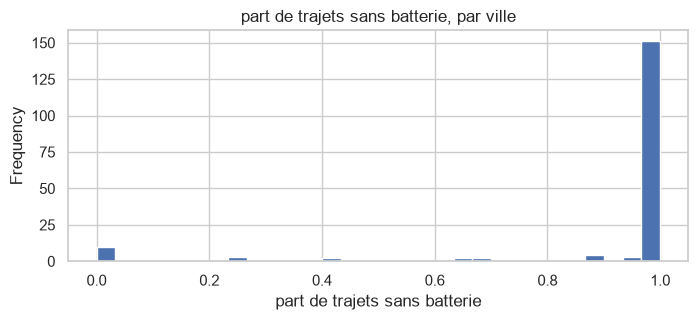

In [3]:
na_city = trips.groupby("city_id")["battery_na"].mean()
na_city.plot.hist(bins=30, figsize=(8, 3), title="part de trajets sans batterie, par ville")
plt.xlabel("part de trajets sans batterie"); plt.show()

### Free-floating selon la règle de la ville

In [4]:
pd.crosstab(trips["return_to_official_only"], trips["free_floating_end"],
            normalize="index").round(3)

free_floating_end,False,True
return_to_official_only,,
False,0.847,0.153
True,0.905,0.095


> **Interprétation :** _à rédiger_

## 2. Distributions des trajets

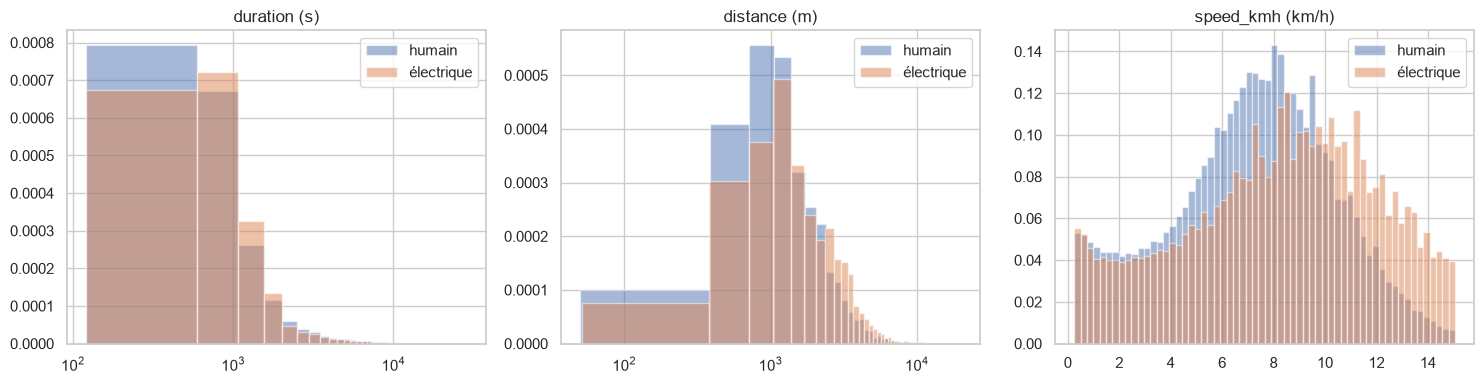

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, unit in zip(axes, ["duration", "distance", "speed_kmh"], ["s", "m", "km/h"]):
    for elec, grp in trips.groupby("is_electric"):
        ax.hist(grp[col], bins=60, alpha=.5, density=True,
                label="électrique" if elec else "humain")
    ax.set_title(f"{col} ({unit})")
    ax.legend()
axes[0].set_xscale("log"); axes[1].set_xscale("log")
plt.tight_layout(); plt.show()

In [6]:
trips.groupby("is_electric")[["duration", "distance", "speed_kmh"]].median()

,duration,distance,speed_kmh
is_electric,,,
False,720.0,1306.599427,7.396115
True,780.0,1671.401698,8.527184


### Répartition de la flotte

In [7]:
trips.drop_duplicates("bike_id").groupby(["form_factor", "propulsion_type"]).size()

form_factor    propulsion_type
bicycle        electric_assist     3202
               human              22572
cargo_bicycle  electric_assist       10
               human                 49
unknown        unknown              591
dtype: int64

> **Interprétation :** _à rédiger_

## 3. Dimension temporelle (heure locale)

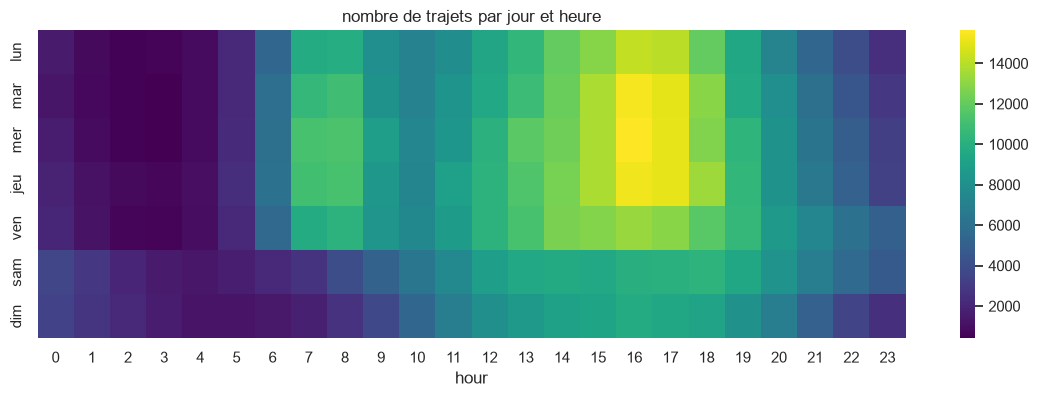

In [8]:
heat = trips.pivot_table(index="weekday", columns="hour", values="bike_id", aggfunc="size")
heat.index = DAYS
plt.figure(figsize=(14, 4))
sns.heatmap(heat, cmap="viridis")
plt.title("nombre de trajets par jour et heure"); plt.show()

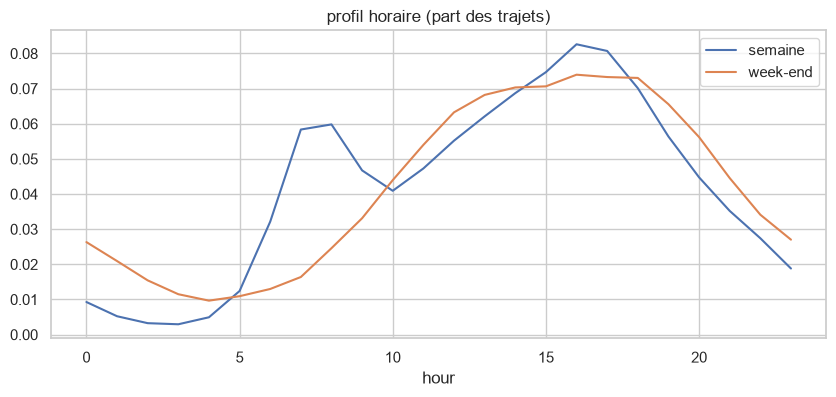

In [9]:
prof = trips.groupby(["is_weekend", "hour"]).size().unstack(0)
(prof / prof.sum()).plot(figsize=(10, 4), title="profil horaire (part des trajets)")
plt.legend(["semaine", "week-end"]); plt.show()

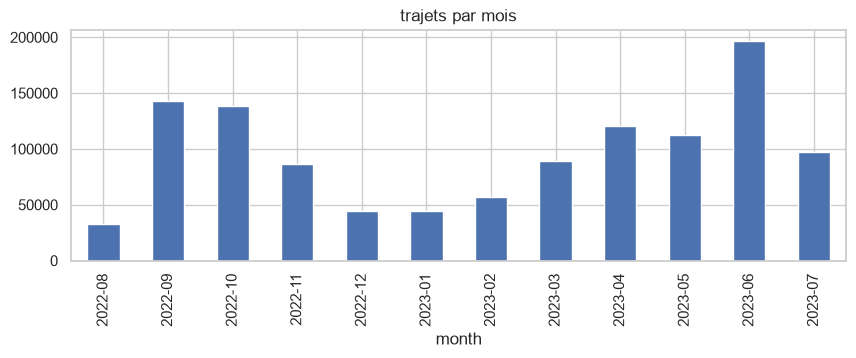

In [10]:
trips.groupby("month").size().plot.bar(figsize=(10, 3), title="trajets par mois")
plt.show()

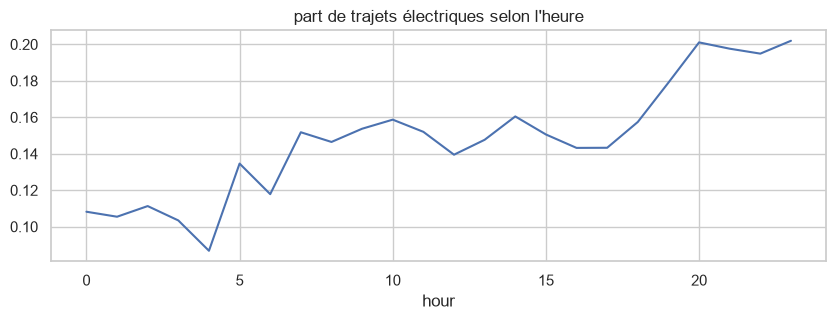

In [11]:
trips.groupby("hour")["is_electric"].mean().plot(
    figsize=(10, 3), title="part de trajets électriques selon l'heure")
plt.show()

> **Interprétation :** _à rédiger_

## 4. Batterie des vélos électriques

batterie qui augmente : 0.019403623912112998
batterie inchangée : 0.2648321206068388


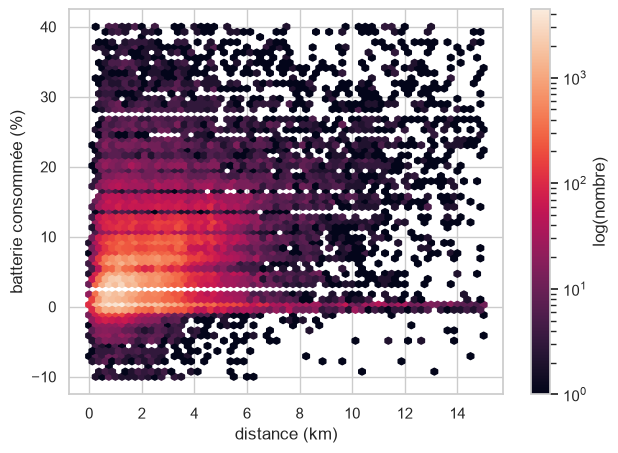

,distance,duration,battery_used
distance,1.000000,0.633166,0.251249
duration,0.633166,1.000000,0.235542
battery_used,0.251249,0.235542,1.000000


In [12]:
elec = trips[trips["is_electric"] == True].dropna(subset=["battery_used"])
print("batterie qui augmente :", (elec["battery_used"] < 0).mean())
print("batterie inchangée :", (elec["battery_used"] == 0).mean())

plt.figure(figsize=(7, 5))
plt.hexbin(elec["distance"] / 1000, elec["battery_used"], gridsize=60, bins="log",
           extent=(0, 15, -10, 40))
plt.xlabel("distance (km)"); plt.ylabel("batterie consommée (%)")
plt.colorbar(label="log(nombre)"); plt.show()

elec[["distance", "duration", "battery_used"]].corr(method="spearman")

> **Interprétation :** _à rédiger_

## 5. Corrélations entre variables des trajets

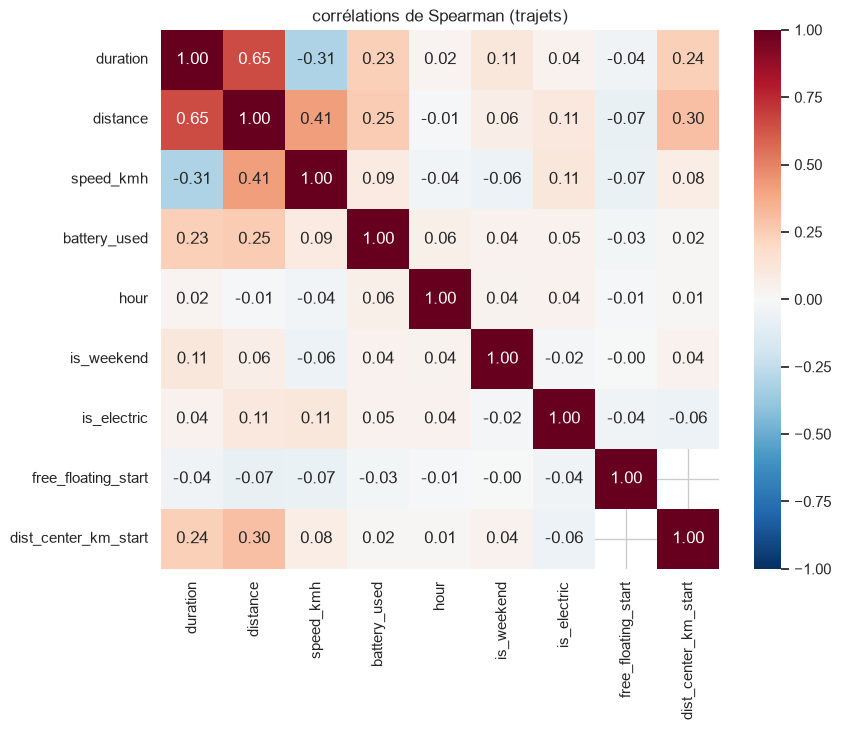

In [13]:
num = ["duration", "distance", "speed_kmh", "battery_used", "hour", "is_weekend",
       "is_electric", "free_floating_start", "dist_center_km_start"]
corr = trips[num].astype(float).corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("corrélations de Spearman (trajets)"); plt.show()

> **Interprétation :** _à rédiger_

## 6. Profils des stations

In [14]:
dep = trips.groupby("station_id_start").size().rename("departures")
arr = trips.groupby("station_id_end").size().rename("arrivals")
morning = trips["hour"].between(6, 9)
evening = trips["hour"].between(16, 19)
dep_m = trips[morning].groupby("station_id_start").size().rename("dep_morning")
arr_m = trips[morning].groupby("station_id_end").size().rename("arr_morning")

occ = status.assign(
        occupancy=status["bikes"] / status["capacity"].where(status["capacity"] > 0),
        empty=status["bikes_available_to_rent"] == 0,
        full=status["free_racks"] == 0)
occ = occ.groupby("station_id")[["occupancy", "empty", "full"]].mean()

st = (stations.set_index("id")[["city_id", "capacity", "is_virtual", "dist_center_km"]]
      .join([dep, arr, dep_m, arr_m, occ]))
st[["departures", "arrivals", "dep_morning", "arr_morning"]] = \
    st[["departures", "arrivals", "dep_morning", "arr_morning"]].fillna(0)
st["net_flow"] = st["arrivals"] - st["departures"]
st["morning_balance"] = (st["arr_morning"] - st["dep_morning"]) / \
                        (st["arr_morning"] + st["dep_morning"]).replace(0, np.nan)
st.describe().T

,count,mean,std,min,25%,50%,75%,max
city_id,2931.0,480.042648,242.722049,7.000000,251.000000,527.000000,702.000000,858.000000
capacity,2931.0,6.056636,6.507979,0.000000,0.000000,6.000000,10.000000,70.000000
dist_center_km,2931.0,5.200233,12.266084,0.004037,0.933156,1.997376,4.788260,251.371213
departures,2931.0,360.101331,624.591988,0.000000,41.000000,149.000000,398.000000,8116.000000
arrivals,2931.0,328.704197,576.265498,0.000000,37.500000,137.000000,368.500000,7721.000000
dep_morning,2931.0,62.879904,166.377731,0.000000,3.000000,19.000000,61.000000,3772.000000
arr_morning,2931.0,57.498465,146.220324,0.000000,3.000000,15.000000,53.500000,2823.000000
occupancy,1695.0,0.567391,0.367416,0.000000,0.375642,0.528984,0.663544,6.486188
empty,2898.0,0.086625,0.110240,0.000000,0.015696,0.047380,0.111111,1.000000
full,2898.0,0.484858,0.457038,0.000000,0.016422,0.295704,1.000000,1.000000


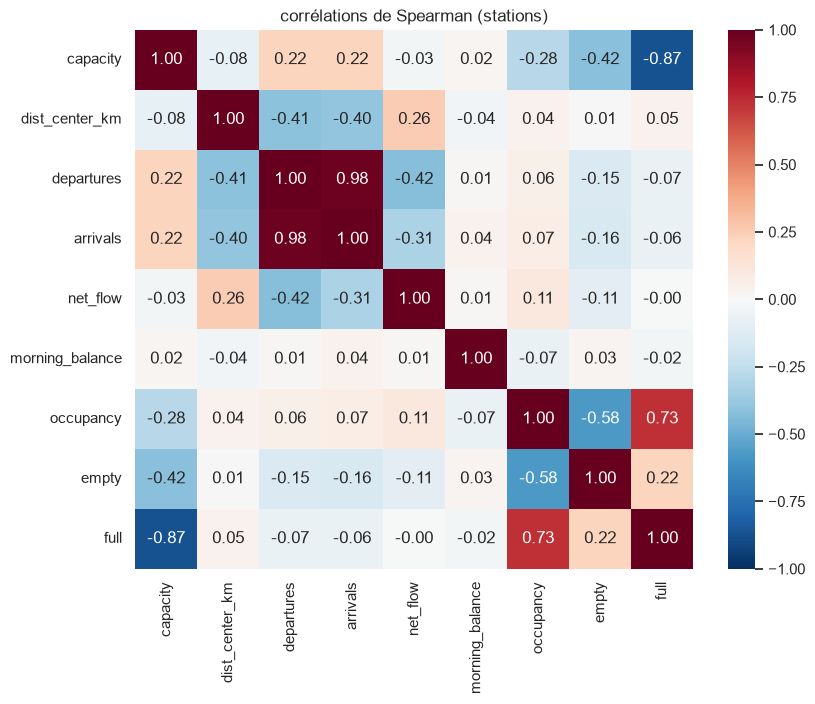

In [15]:
cols = ["capacity", "dist_center_km", "departures", "arrivals", "net_flow",
        "morning_balance", "occupancy", "empty", "full"]
plt.figure(figsize=(9, 7))
sns.heatmap(st[cols].astype(float).corr(method="spearman"), annot=True, fmt=".2f",
            cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("corrélations de Spearman (stations)"); plt.show()

### Bilan du matin pour la ville la plus active

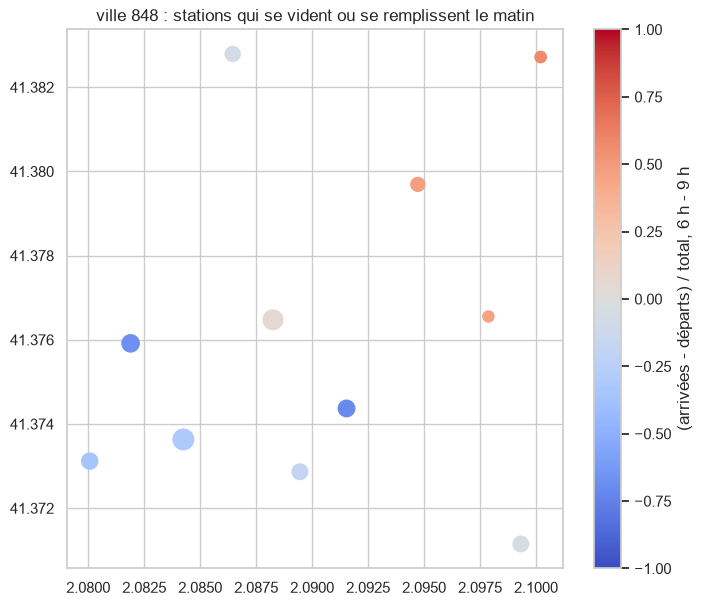

In [16]:
top_city = trips["city_id"].value_counts().index[0]
s = st[(st["city_id"] == top_city) & (st["dep_morning"] + st["arr_morning"] >= 20)]
s = s.join(stations.set_index("id")[["lat", "lon"]])
plt.figure(figsize=(8, 7))
plt.scatter(s["lon"], s["lat"], c=s["morning_balance"], cmap="coolwarm", vmin=-1, vmax=1,
            s=20 + s["dep_morning"] / s["dep_morning"].max() * 200)
plt.colorbar(label="(arrivées - départs) / total, 6 h - 9 h")
plt.title(f"ville {top_city} : stations qui se vident ou se remplissent le matin")
plt.show()

> **Interprétation :** _à rédiger_

## 7. Relevés des stations

### Taux de stations vides et pleines selon l'heure

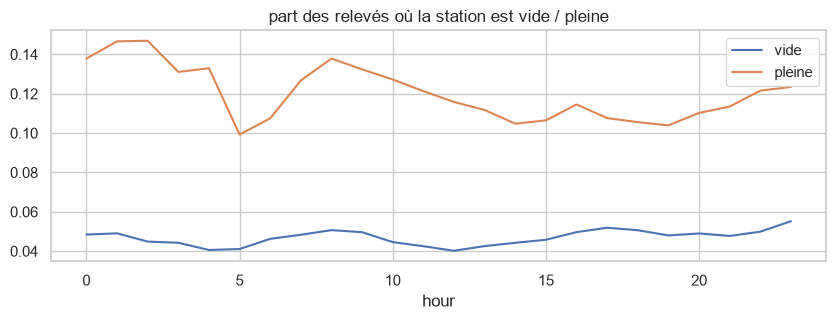

In [17]:
s_ok = status[~status["maintenance"] & ~status["is_virtual"].fillna(False)]
rates = s_ok.groupby("hour").agg(
    vide=("bikes_available_to_rent", lambda x: (x == 0).mean()),
    pleine=("free_racks", lambda x: (x == 0).mean()))
rates.plot(figsize=(10, 3), title="part des relevés où la station est vide / pleine")
plt.show()

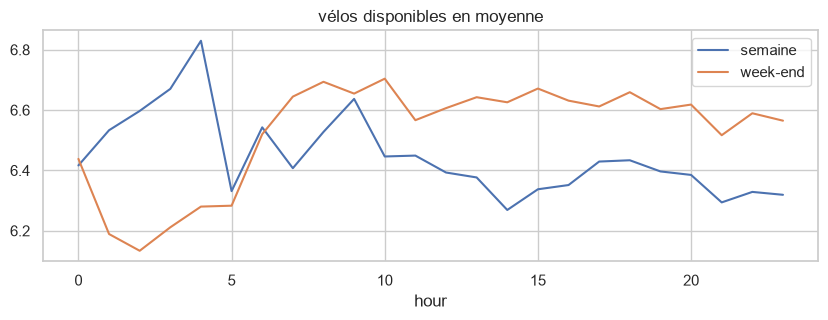

In [18]:
s_ok.groupby(["is_weekend", "hour"])["bikes_available_to_rent"].mean().unstack(0).plot(
    figsize=(10, 3), title="vélos disponibles en moyenne")
plt.legend(["semaine", "week-end"]); plt.show()

### Série horaire régulière : autocorrélation et prédiction naïve

In [19]:
rng = np.random.default_rng(0)
ids = status.loc[status["enough_snapshots"], "station_id"].unique()
sample = rng.choice(ids, size=min(300, len(ids)), replace=False)

hourly = (status[status["station_id"].isin(sample)]
          .set_index("time")
          .groupby("station_id")["bikes_available_to_rent"]
          .resample("1h").last()
          .groupby(level=0).ffill()
          .rename("y").reset_index())
hourly["y_next"] = hourly.groupby("station_id")["y"].shift(-1)
hourly = hourly.dropna()

ac = hourly.groupby("station_id").apply(lambda g: g["y"].autocorr(lag=1))
print("autocorrélation à 1 h, médiane :", ac.median())
print("MAE de la prédiction naïve (même valeur dans 1 h) :",
      (hourly["y_next"] - hourly["y"]).abs().mean())
print("part des heures sans aucun changement :", (hourly["y_next"] == hourly["y"]).mean())

autocorrélation à 1 h, médiane : 0.9842658766214325
MAE de la prédiction naïve (même valeur dans 1 h) : 0.12696265449800098
part des heures sans aucun changement : 0.918071902351445


> **Interprétation :** _à rédiger_